# Calibración KYC contaminada: cota y coste
## Resumen
Se compara el rango ordinario con una envolvente que requiere cota externa válida del número de contaminantes. Las tasas se calculan abajo. Datos sintéticos; no estima fraude real.

## Método y supuestos
Score fijo, referencia con c contaminantes, c≤m<n, y n−c scores limpios intercambiables con el próximo inlier. El subconjunto limpio no se elige por sus propios scores.

Con k scores observados ≥s, usamos $p_m(s)=\min(1,(1+k)/(n-m+1))$. Sea k0 el conteo limpio: k≥k0 y n−m≤n−c, por lo que p_m domina el p limpio. La inclusión {p_m≤α}⊆{p_limpio≤α} transmite validez marginal. No se garantiza FPR de una calibración fijada, validez individual ni FDR de lote. La cota m no se estima aquí.

In [1]:
import csv, json
from pathlib import Path
from IPython.display import display, Image
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
print(json.dumps(metrics,indent=2))

{
  "config": {
    "seeds": 80,
    "calibration_size": 499,
    "test_inliers": 2000,
    "test_outliers": 500,
    "alpha": 0.05,
    "contamination_fraction": 0.4,
    "anomaly_shift": 3,
    "hypothesis": "under low-score contamination, robust mean FPR <=0.055 and baseline minus robust >=0.02",
    "scenarios": [
      "clean",
      "low-score-contamination",
      "understated-bound",
      "high-score-contamination"
    ]
  },
  "hypothesis_passed": true,
  "seconds": 5.879069489999949,
  "tracemalloc_peak_bytes": 1198773,
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "platform": "Linux-6.18.55-x86_64-with-glibc2.39",
  "numpy": "2.3.5",
  "matplotlib": "3.10.8",
  "processor": "x86_64",
  "logical_cpus": 9
}


## Datos y resultados
80 semillas; n=499, c=199 en escenarios contaminados. Mismos scores de prueba en ambos métodos y escenarios. Barras de error son ±1,96 SE de la media entre semillas independientes; no intervalos individuales ni por cliente.

{'scenario': 'clean', 'method': 'ordinary', 'kind': 'inlier', 'mean': '0.05017499999999999', 'se_seeds': '0.0011909169693341771'}
{'scenario': 'clean', 'method': 'ordinary', 'kind': 'outlier', 'mean': '0.8487749999999998', 'se_seeds': '0.0024865444860313005'}
{'scenario': 'clean', 'method': 'guard', 'kind': 'inlier', 'mean': '0.0309125', 'se_seeds': '0.0008959638311387692'}
{'scenario': 'clean', 'method': 'guard', 'kind': 'outlier', 'mean': '0.795425', 'se_seeds': '0.0035589419829458696'}
{'scenario': 'low-score-contamination', 'method': 'ordinary', 'kind': 'inlier', 'mean': '0.08346250000000001', 'se_seeds': '0.0018852100703883564'}
{'scenario': 'low-score-contamination', 'method': 'ordinary', 'kind': 'outlier', 'mean': '0.8957750000000001', 'se_seeds': '0.00242272828475918'}
{'scenario': 'low-score-contamination', 'method': 'guard', 'kind': 'inlier', 'mean': '0.050068749999999995', 'se_seeds': '0.0015505395077300176'}
{'scenario': 'low-score-contamination', 'method': 'guard', 'kind':

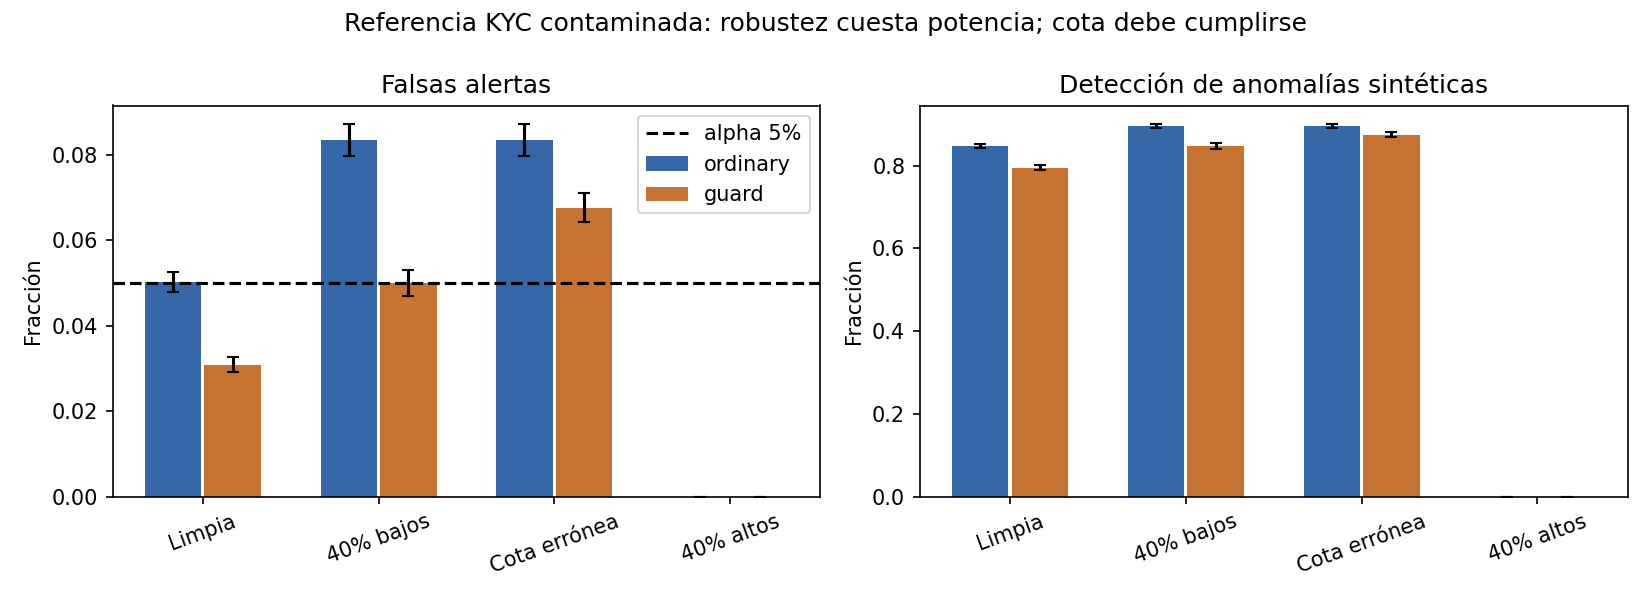

In [2]:
rows=list(csv.DictReader((root/'results/summary.csv').open()))
for row in rows: print(row)
display(Image(filename=str(root/'results/audit.png')))

## Falsación y comprobaciones
Una cota subestimada m=99 frente a c=199 rompe el supuesto. Contaminación de scores altos conserva tipo I a costa de potencia nula. En limpio, una cota excesiva es conservadora y pierde potencia.

In [3]:
from src.guard import ContaminationGuard
assert metrics['hypothesis_passed']
assert ContaminationGuard([1.,2.,2.,3.],1).p_value(4.)==.25
assert ContaminationGuard([1.,2.,2.,3.]).p_value(2.)==.8
for row in csv.DictReader((root/'results/performance.csv').open()): print(row)
print('Checks passed')

{'n': '100', 'fit_seconds': '1.0615999997298786e-05', 'queries': '10000', 'query_seconds': '0.003219596000008096'}
{'n': '1000', 'fit_seconds': '4.245400003810573e-05', 'queries': '10000', 'query_seconds': '0.004172176999986732'}
{'n': '10000', 'fit_seconds': '0.0003880419999973128', 'queries': '10000', 'query_seconds': '0.005057556999986446'}
Checks passed


## Conclusión y límites
La corrección reduce falsas alertas bajo la cota correcta, pero no descubre cuántos contaminantes hay. Solo justifica un piloto de auditoría con referencias adjudicadas, no rechazo automático. No es un algoritmo nuevo de la literatura ni un sistema operativo. Véase informe.md y cinco fuentes verificadas en referencias.bib.